In [1]:
import os
import time
from datetime import datetime
import anndata as ad
import squidpy as sq
import pandas as pd
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.preprocessing import LabelEncoder
import squidpy as sq
import scib
import anndata


In [2]:
from banksy.main import median_dist_to_nearest_neighbour
from banksy_utils.load_data import load_adata, display_adata
from banksy_utils.filter_utils import normalize_total, filter_hvg, print_max_min
from banksy_utils.filter_utils import filter_cells
from banksy.main import median_dist_to_nearest_neighbour
from banksy.initialize_banksy import initialize_banksy
from banksy.embed_banksy import generate_banksy_matrix


In [3]:
data_folder_path = "../"
benchmarking_folder_path = "../benchmarking/"
figure_folder_path = f"../figures_banksy_nanostring/"
result_directory = '../results/'

In [4]:
model_name = "banksy"
latent_key = f"{model_name}_latent"
leiden_resolution = 0.5 # used for Leiden clustering of latent space
random_seed = 0 # used for Leiden clustering


In [5]:
# set Banksy params
# ==========
plot_graph_weights = False
k_geom = 15 # number of spatial neighbours
max_m = 1 # use both mean and AFT
nbr_weight_decay = "scaled_gaussian" # can also choose "reciprocal", "uniform" or "ranked"
pca_dims = [20]  # Dimensionality in which PCA reduces to
lambda_list = [0.2]  # list of lambda parameters
coord_keys = ('x_coord', 'y_coord', 'xy_coord')

In [6]:
def load_data(adata, coord_keys = coord_keys, preprocess = False):
    x_coord, y_coord, xy_coord = coord_keys[0], coord_keys[1], coord_keys[2]
    adata.obs['x_coord'] = adata.obsm['spatial'][:, 0]
    adata.obs['y_coord'] = adata.obsm['spatial'][:, 1]

    raw_y, raw_x = adata.obs[y_coord], adata.obs[x_coord]
    print('raw x and y')
    adata.obsm[xy_coord] = np.vstack((adata.obs[x_coord].values,adata.obs[y_coord].values)).T
    print('coord done')
    if preprocess:
        adata.var_names_make_unique()
        adata.var["mt"] = adata.var_names.str.startswith("MT-")
        sc.pp.calculate_qc_metrics(adata, 
                           qc_vars=["mt"], 
                           log1p=True, 
                           inplace=True)
        # Filter cells with each respective filters
        adata = filter_cells(adata, 
             min_count=50, 
             max_count=2500, 
             MT_filter=20, 
             gene_filter=10)
        adata = normalize_total(adata)
        adata, adata_allgenes = filter_hvg(
                                adata,
                                n_top_genes=2000,
                                flavor="seurat")
        
    return raw_y, raw_x , adata


In [7]:
def get_banksy_embedding(adata, k_geom):
    nbrs = median_dist_to_nearest_neighbour(adata, key = coord_keys[2])

    banksy_dict = initialize_banksy(
        adata,
        coord_keys,
        k_geom,
        nbr_weight_decay=nbr_weight_decay,
        max_m=max_m,
        plt_edge_hist=False,
        plt_nbr_weights=False,
        plt_agf_angles=False, # takes long time to plot
        plt_theta=False)


    banksy_dict, banksy_matrix = generate_banksy_matrix(adata,
                                                    banksy_dict,
                                                    lambda_list,
                                                    max_m)
    return banksy_dict, banksy_matrix

In [9]:
def run_classifier(banksy_embedding, label_cats, cell_type_key,run_num):
    scores = []
    for label_cat in label_cats:
          label_encoder = LabelEncoder()
          labels = np.array(
              label_encoder.fit_transform(adata.obs[label_cat]))
          for random_state in range(4):
                np.random.seed(random_state)

                indices = np.arange(adata.X.shape[0])
                np.random.shuffle(indices)
                num_train = int(0.8 * len(indices))
                train_indices = indices[:num_train]
                test_indices = indices[num_train:]
                labels_train = labels[train_indices]
                labels_test = labels[test_indices]
                X = banksy_embedding.X
                X_train = X[train_indices]
                X_test = X[test_indices]

                lr_clf = LogisticRegression()
                lr_clf.fit(X_train, labels_train)
                train_predictions = lr_clf.predict(X_train)
                train_f1 = f1_score(labels_train, train_predictions, average="weighted")
                train_score = lr_clf.score(X_train, labels_train)
                test_predictions = lr_clf.predict(X_test)
                test_f1 = f1_score(labels_test, test_predictions, average="weighted")
                test_score = lr_clf.score(X_test, labels_test)
                scores.append({
                            "clf_task": label_cat,
                            "random_state": random_state,
                            "run_number": run_num,
                            "clf_category": "train",
                            "f1_score": train_f1,
                            "accuracy": train_score})

                scores.append({
                            "clf_task": label_cat,
                            "random_state": random_state,
                            "run_number" : run_num,
                            "clf_category": "test",
                            "f1_score": test_f1,
                            "accuracy": test_score})
    return scores


In [11]:
def get_clusters(adata,label_cats, cell_type_key, run_num, k_geom, dataset_name, plot_latent_umaps= False):
    scores = []
    for label_cat in label_cats:
          sc.pp.neighbors(adata, n_neighbors=k_geom)

          sc.tl.leiden(adata=adata,
                         resolution=leiden_resolution,
                         random_state=random_seed,
                         key_added=f"latent_{model_name}_run_{str(run_num)}_leiden_{str(leiden_resolution)}")

          nmi_score = scib.metrics.ari(adata, cluster_key=f"latent_{model_name}_run_{str(run_num)}_leiden_{str(leiden_resolution)}", label_key=label_cat)
          ari_score = scib.metrics.nmi(adata, cluster_key=f"latent_{model_name}_run_{str(run_num)}_leiden_{str(leiden_resolution)}", label_key=label_cat)
          scores.append({
                            "n_neighbors": k_geom,
                            "run_number": run_num,
                            "clf_category": label_cat,
                            "nmi_score": nmi_score,
                            "ari_score": ari_score})
            
    if plot_latent_umaps:
          os.makedirs(f"{figure_folder_path}/{dataset_name}", exist_ok=True)
          sc.tl.umap(adata)
          fig = sc.pl.umap(adata,
                            color=[label_cats[0]],
                            title="Latent Space with Cell Types: Banksy",
                            return_fig=True)
            
          fig.savefig(f"{figure_folder_path}/{dataset_name}/savefiglatent_{model_name}"
                      f"_cell_types_run{run_num}.png",
                      bbox_inches="tight")

            # Create subplot of latent Leiden cluster annotations in physical and latent space
          fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(6, 12))
          title = fig.suptitle(t="Latent and Physical Space with Leiden Clusters: Banksy")
          sc.pl.umap(adata=adata,
                      color=[f"latent_{model_name}_run_{str(run_num)}_leiden_{str(leiden_resolution)}"],
                      title=f"Latent Space with Leiden Clusters",
                      ax=axs[0],
                      show=False)
          sq.pl.spatial_scatter(adata=adata,
                                color=[f"latent_{model_name}_run_{str(run_num)}_leiden_{str(leiden_resolution)}"],
                                title=f"Physical Space with Leiden Clusters",
                                shape=None,
                                ax=axs[1])

        # Create and position shared legend
          handles, labels = axs[0].get_legend_handles_labels()
          lgd = fig.legend(handles, labels, bbox_to_anchor=(1.25, 0.9185))
          axs[0].get_legend().remove()
          axs[1].get_legend().remove()

        # Adjust, save and display plot
          plt.subplots_adjust(wspace=0, hspace=0.2)
          fig.savefig(f"{figure_folder_path}/{dataset_name}/latent_physical_comparison_"
                    f"{model_name}_run{run_num}.png",
                    bbox_extra_artists=(lgd, title),
                    bbox_inches="tight")
          plt.show()

    return scores

In [12]:
def train_banksy(adata,dataset_name ,label_cats, cell_type_key , k_geoms_list = [4, 4, 8, 8,12, 12,16, 16], n_start_run=1,n_end_run=8):
    scores_classifications = []
    scores_clusterings = []

    for run_number, k_geom in zip(np.arange(n_start_run, n_end_run+1), k_geoms_list):
        banksy_dict , banksy_embedding_matrix = get_banksy_embedding(adata, k_geom)
        banksy_embedding_matrix.obsm['spatial'] = adata.obsm['spatial']
        scores_clustering = get_clusters(banksy_embedding_matrix, label_cats, cell_type_key, run_number, k_geom, dataset_name, plot_latent_umaps= True)
        scores_classification = run_classifier(banksy_embedding_matrix, label_cats, cell_type_key, run_number)
        scores_classifications.extend(scores_classification)
        scores_clusterings.extend(scores_clustering)


    os.makedirs(f"{result_directory}/{dataset_name}", exist_ok=True)
    scores_classification_df = pd.DataFrame(scores_classifications)
    scores_clusterings_df = pd.DataFrame(scores_clusterings)
    scores_classification_df.to_csv(f"{result_directory}/{dataset_name}/result_classification_banksy.csv", index=False, sep='\t')
    scores_clusterings_df.to_csv(f"{result_directory}/{dataset_name}/result_clustering_banksy.csv", index=False, sep='\t')

        
       

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/__init__.py:51: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(



Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.02 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.27 s ----

---- Ran generate_spatial_distance_graph in 0.03 s ----

---- Ran theta_from_spatial_graph in 0.07 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.35 s ----

Runtime Jul-04-2024-10-28

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


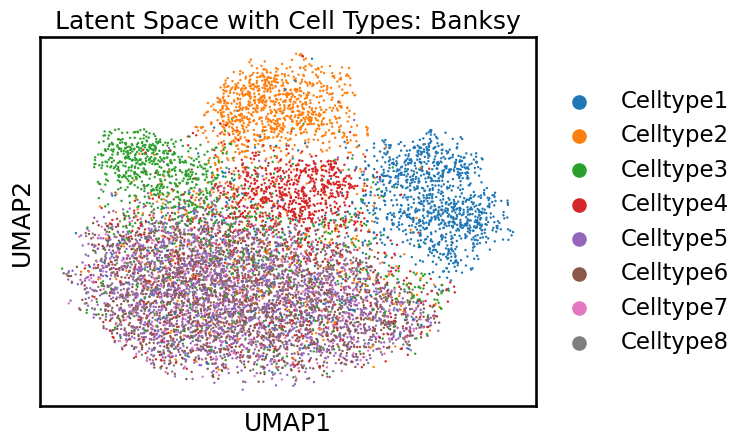

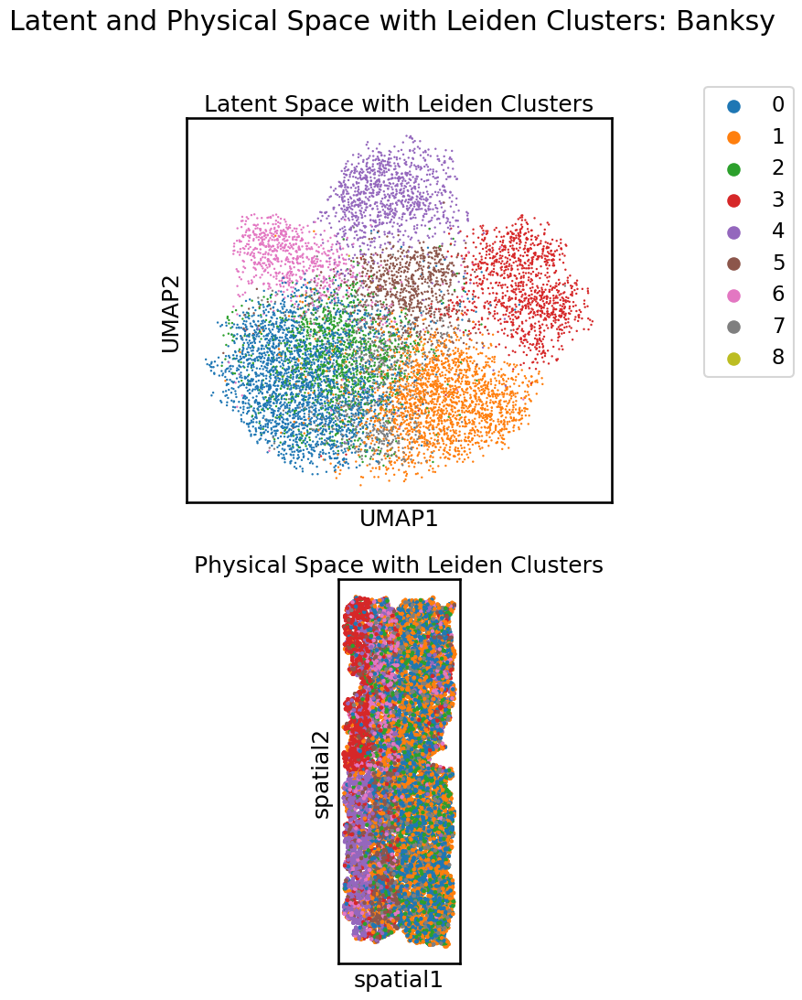

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stab


Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.02 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.27 s ----

---- Ran generate_spatial_distance_graph in 0.03 s ----

---- Ran theta_from_spatial_graph in 0.07 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.36 s ----

Runtime Jul-04-2024-10-29

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


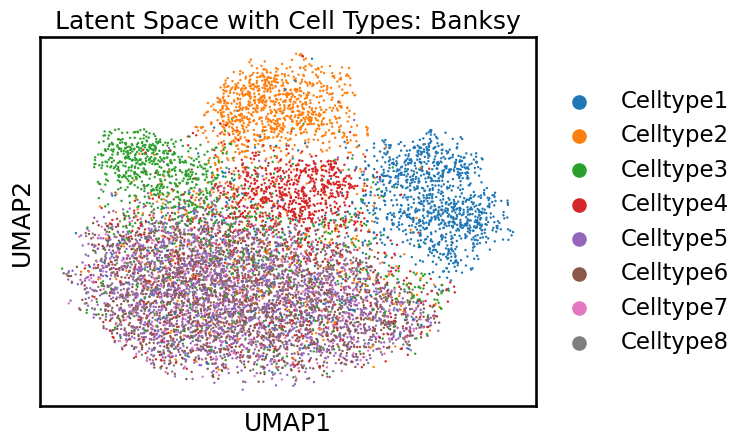

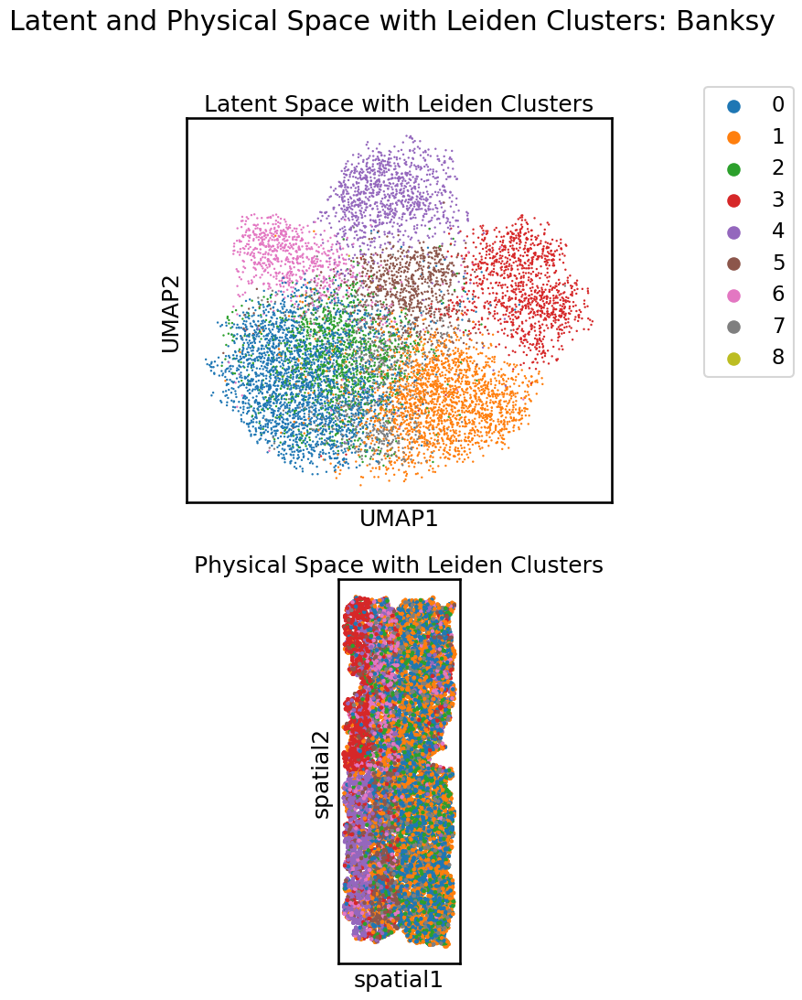

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stab


Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.03 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.29 s ----

---- Ran generate_spatial_distance_graph in 0.04 s ----

---- Ran theta_from_spatial_graph in 0.07 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.38 s ----

Runtime Jul-04-2024-10-30

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


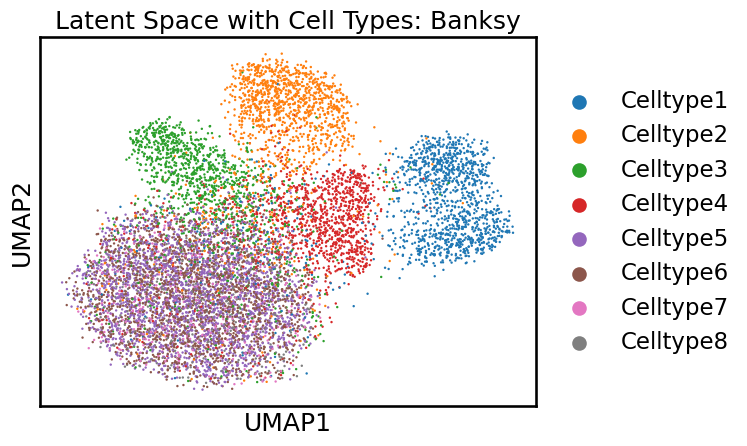

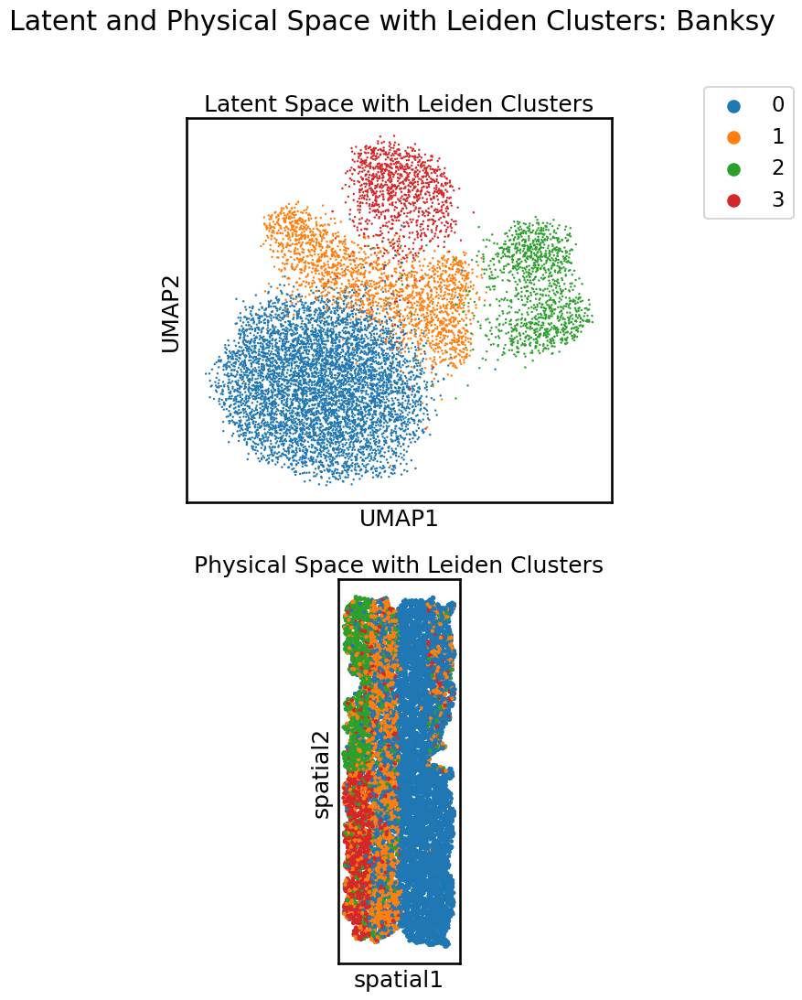


Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.03 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.28 s ----

---- Ran generate_spatial_distance_graph in 0.04 s ----

---- Ran theta_from_spatial_graph in 0.07 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.36 s ----

Runtime Jul-04-2024-10-32

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


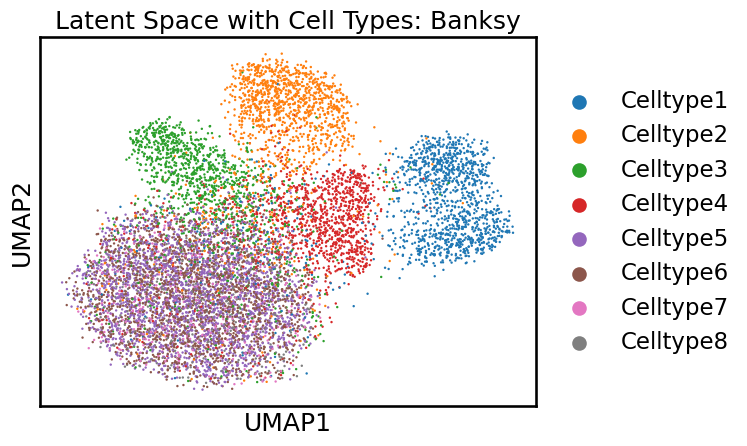

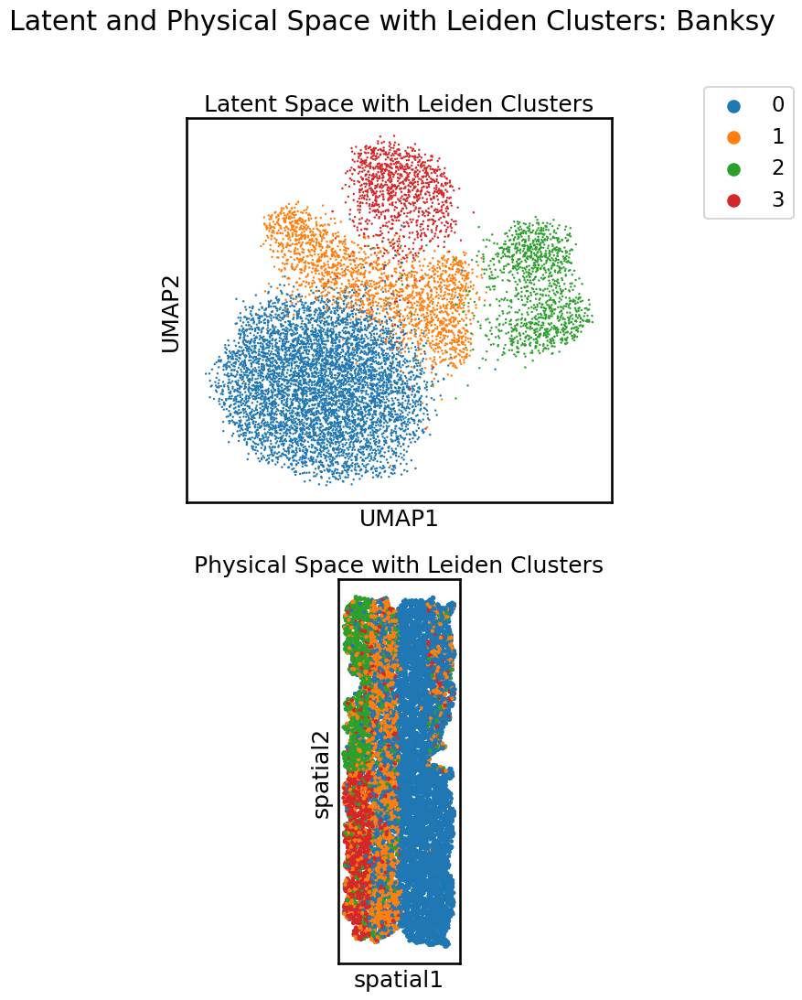


Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.03 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.28 s ----

---- Ran generate_spatial_distance_graph in 0.04 s ----

---- Ran theta_from_spatial_graph in 0.07 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.38 s ----

Runtime Jul-04-2024-10-33

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


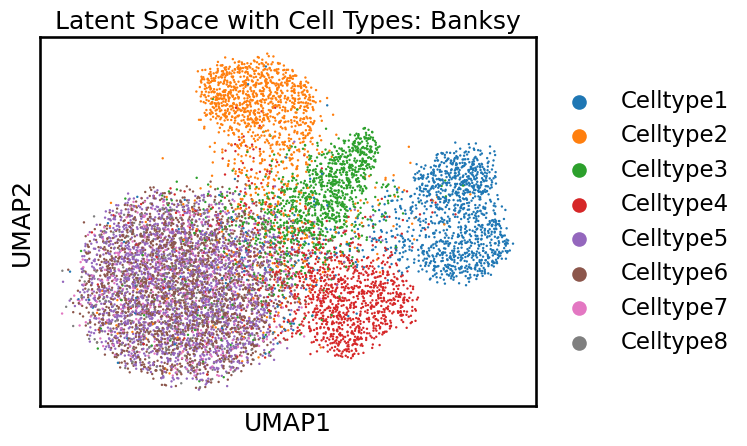

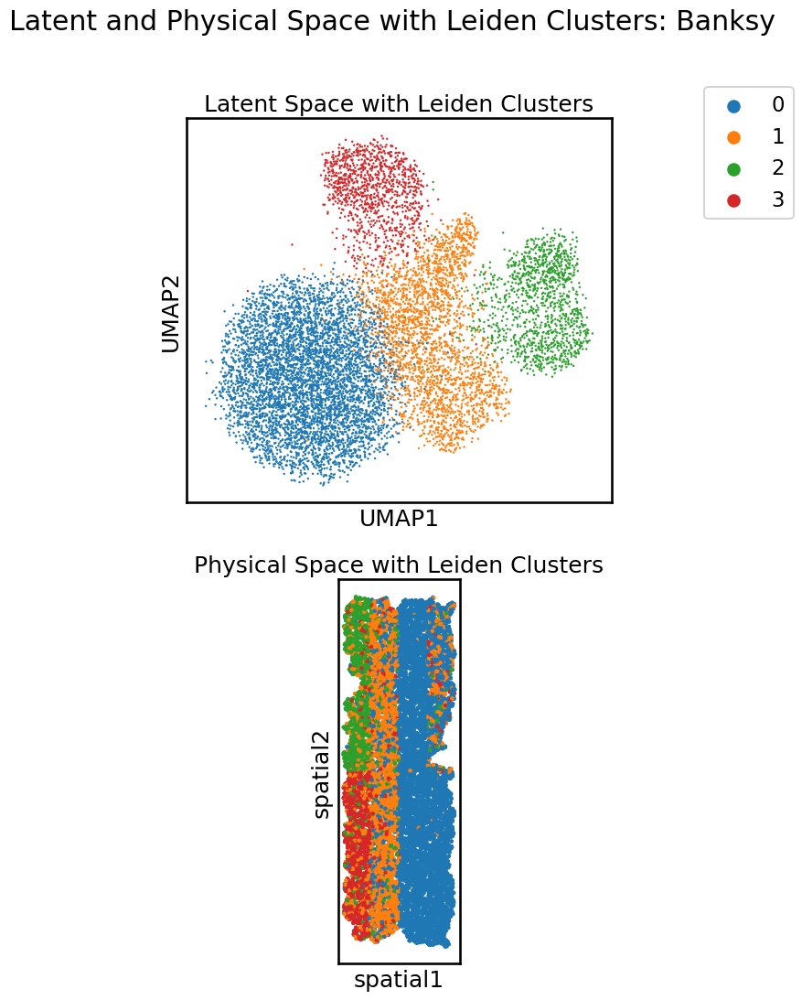


Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.03 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.29 s ----

---- Ran generate_spatial_distance_graph in 0.04 s ----

---- Ran theta_from_spatial_graph in 0.07 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.37 s ----

Runtime Jul-04-2024-10-35

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


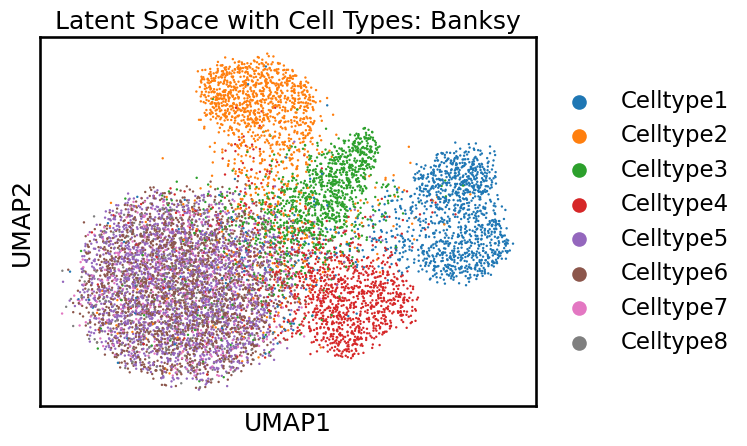

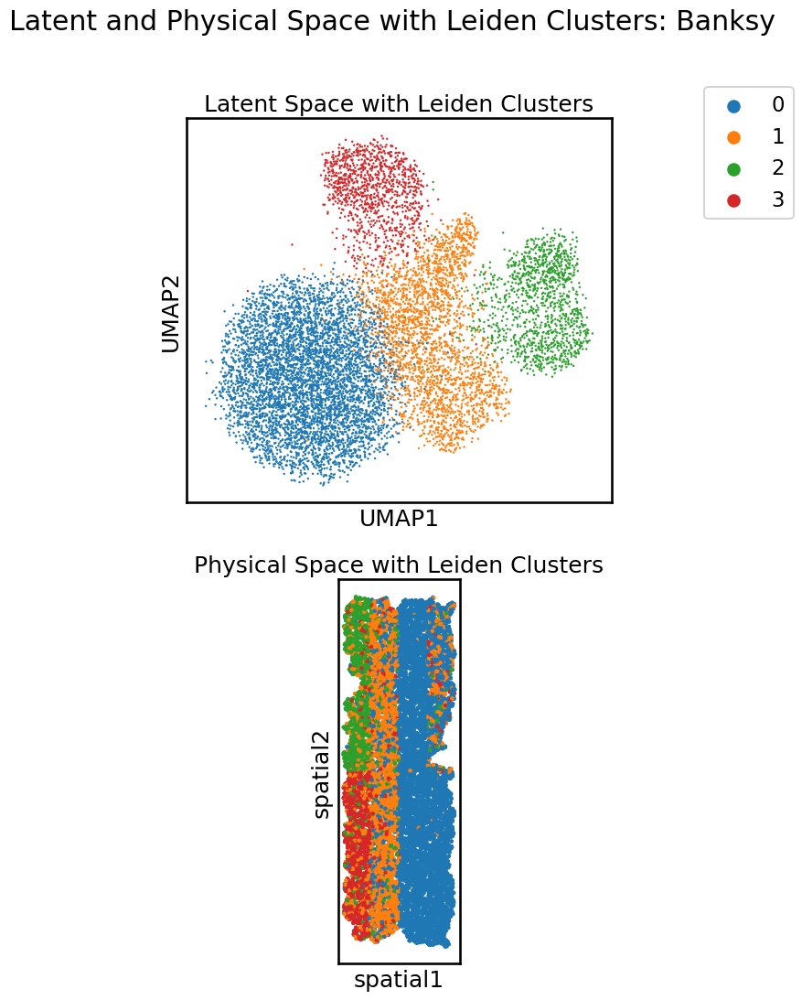


Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.04 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.31 s ----

---- Ran generate_spatial_distance_graph in 0.06 s ----

---- Ran theta_from_spatial_graph in 0.08 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.42 s ----

Runtime Jul-04-2024-10-36

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


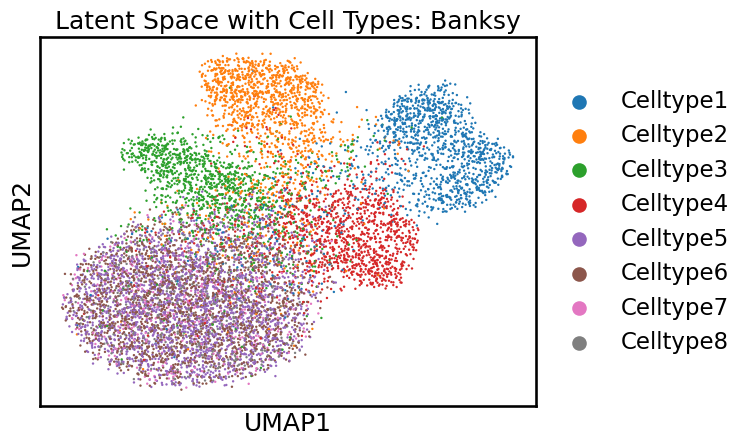

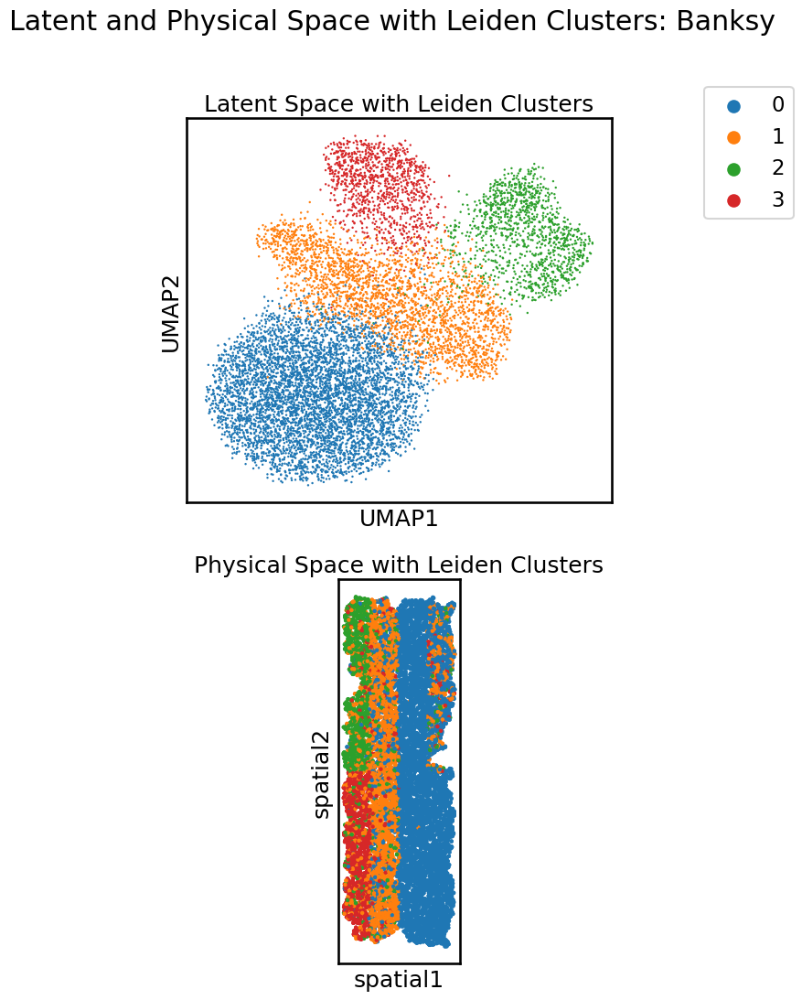


Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 10.176459033246001

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.04 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.29 s ----

---- Ran generate_spatial_distance_graph in 0.05 s ----

---- Ran theta_from_spatial_graph in 0.07 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.40 s ----

Runtime Jul-04-2024-10-38

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


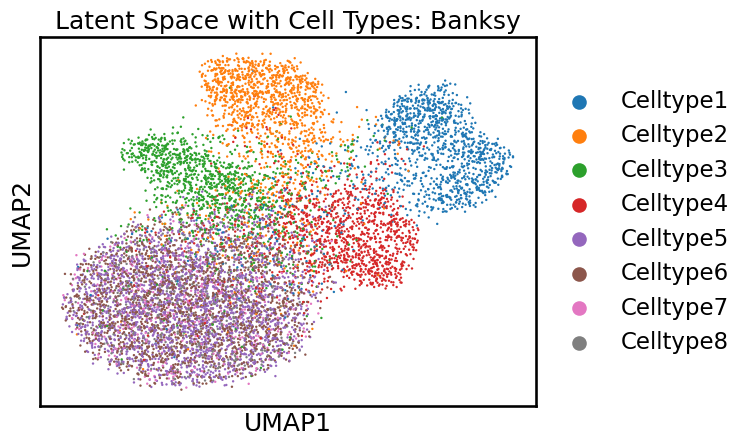

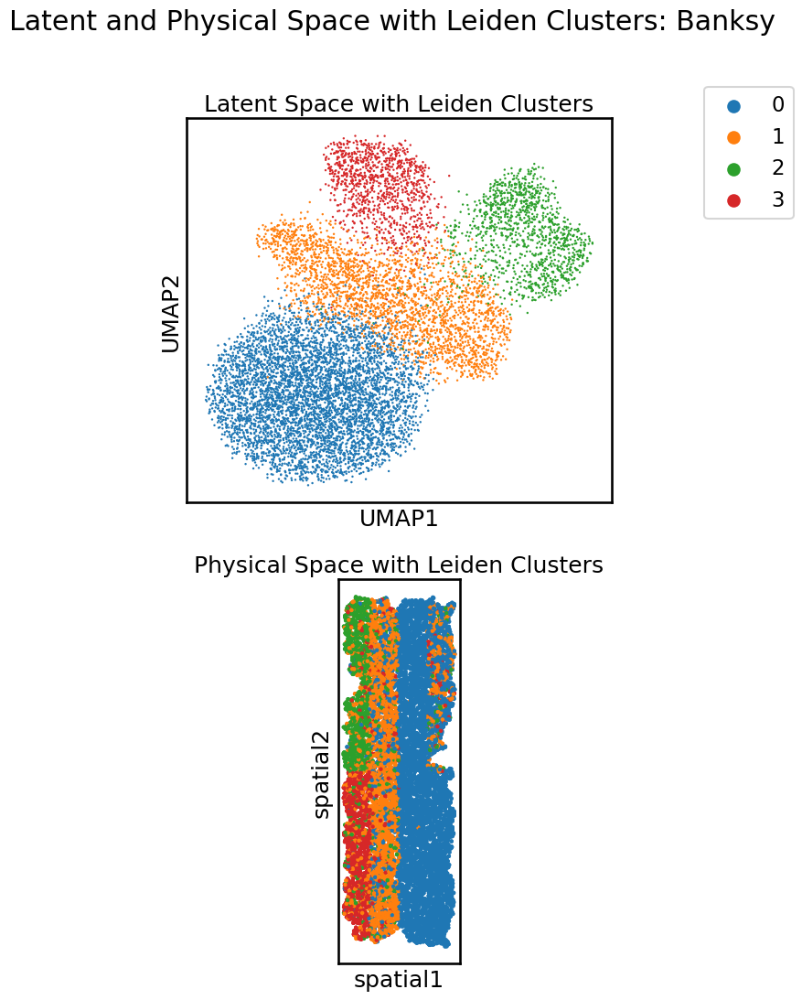

In [53]:
adata = sc.read('../sim_free_1354fts_10000locs_8r_8c_20p_3fc.h5ad')
dataset_name = 'sim_free_1354fts_10000locs_8r_8c_20p_3fc'
label_cats = ["cell_types", "niche_types"]
cell_type_key =label_cats[0]
raw_y, raw_x , adata = load_data(adata, coord_keys = coord_keys, preprocess = False)
train_banksy(adata,dataset_name, label_cats, cell_type_key)

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/__init__.py:51: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(



Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.02 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.29 s ----

---- Ran generate_spatial_distance_graph in 0.03 s ----

---- Ran theta_from_spatial_graph in 0.07 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.36 s ----

Runtime Jul-04-2024-10-40

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


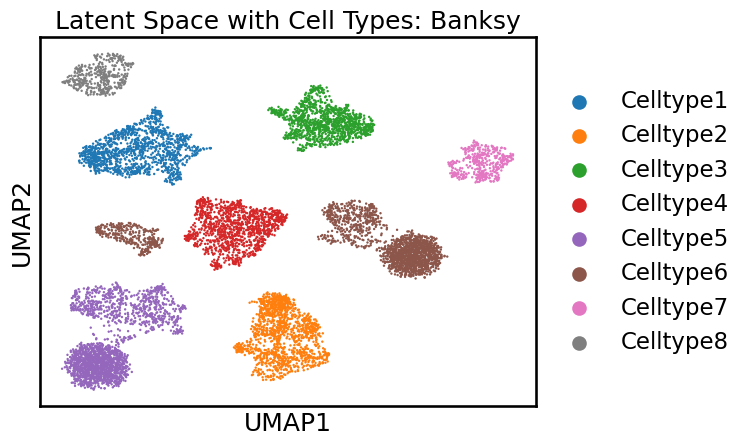

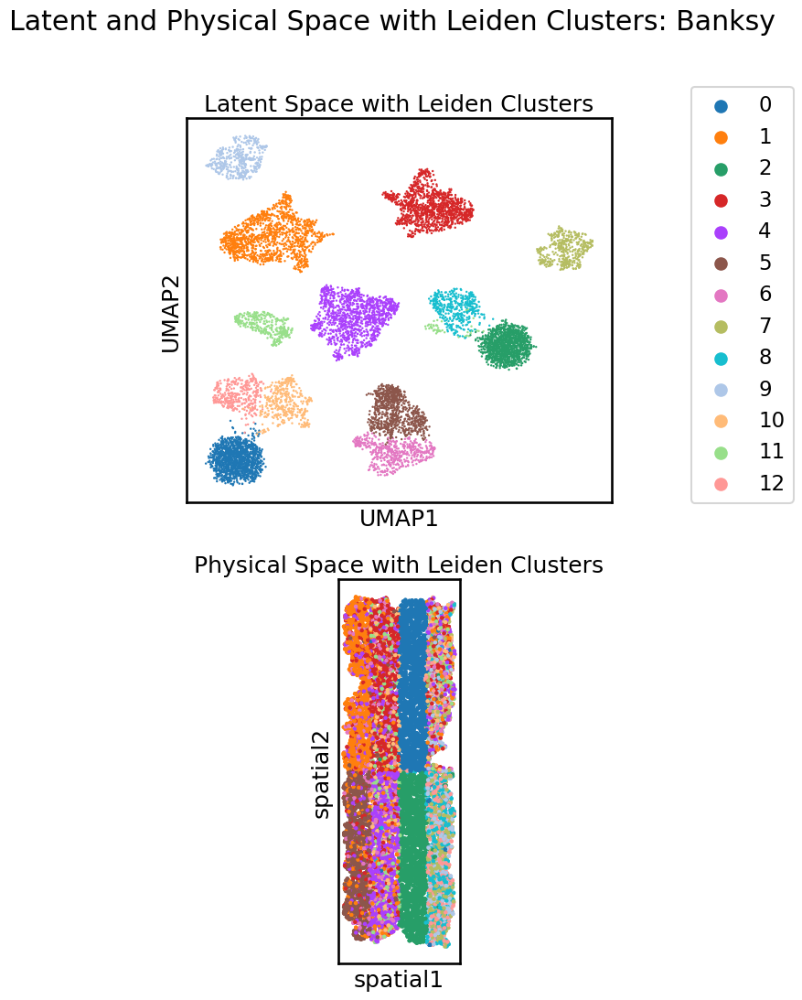


Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.02 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.27 s ----

---- Ran generate_spatial_distance_graph in 0.02 s ----

---- Ran theta_from_spatial_graph in 0.07 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.35 s ----

Runtime Jul-04-2024-10-40

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


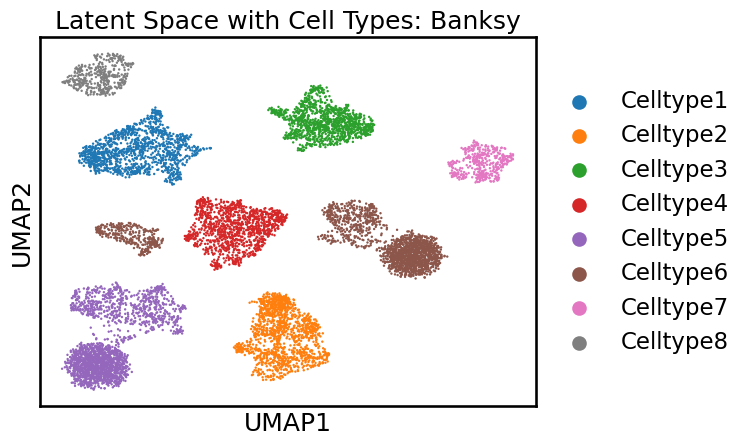

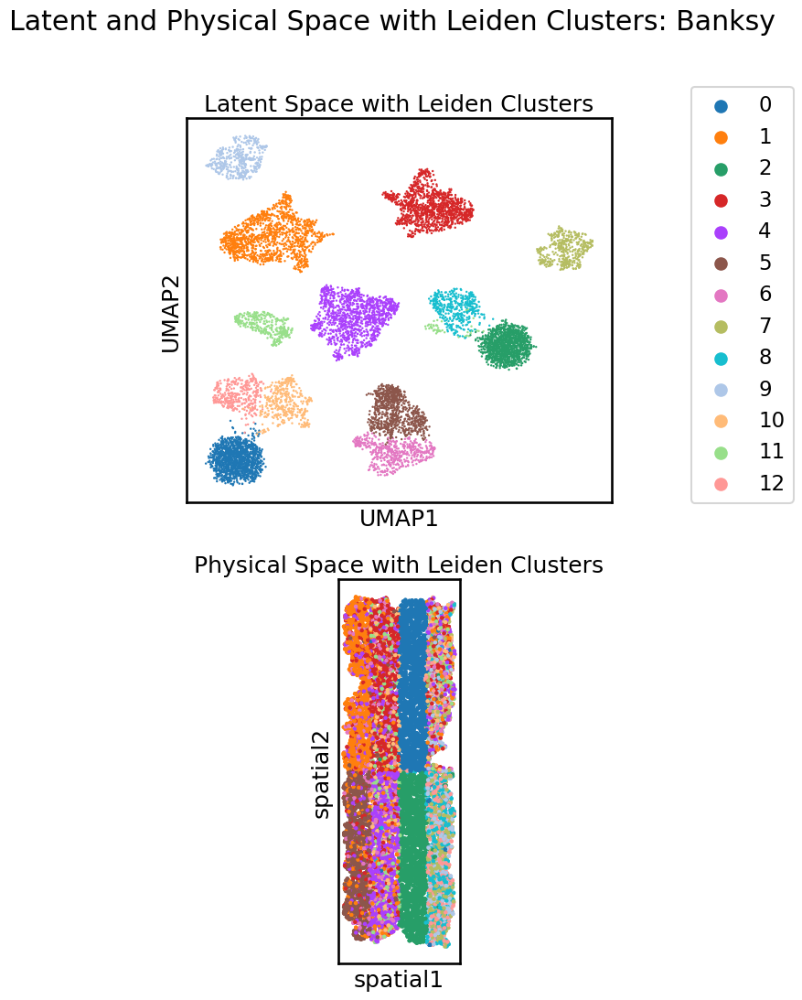


Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.02 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.28 s ----

---- Ran generate_spatial_distance_graph in 0.04 s ----

---- Ran theta_from_spatial_graph in 0.07 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.36 s ----

Runtime Jul-04-2024-10-41

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


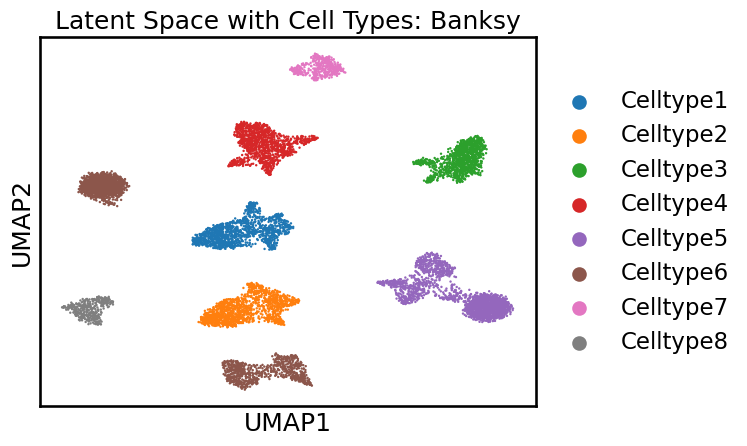

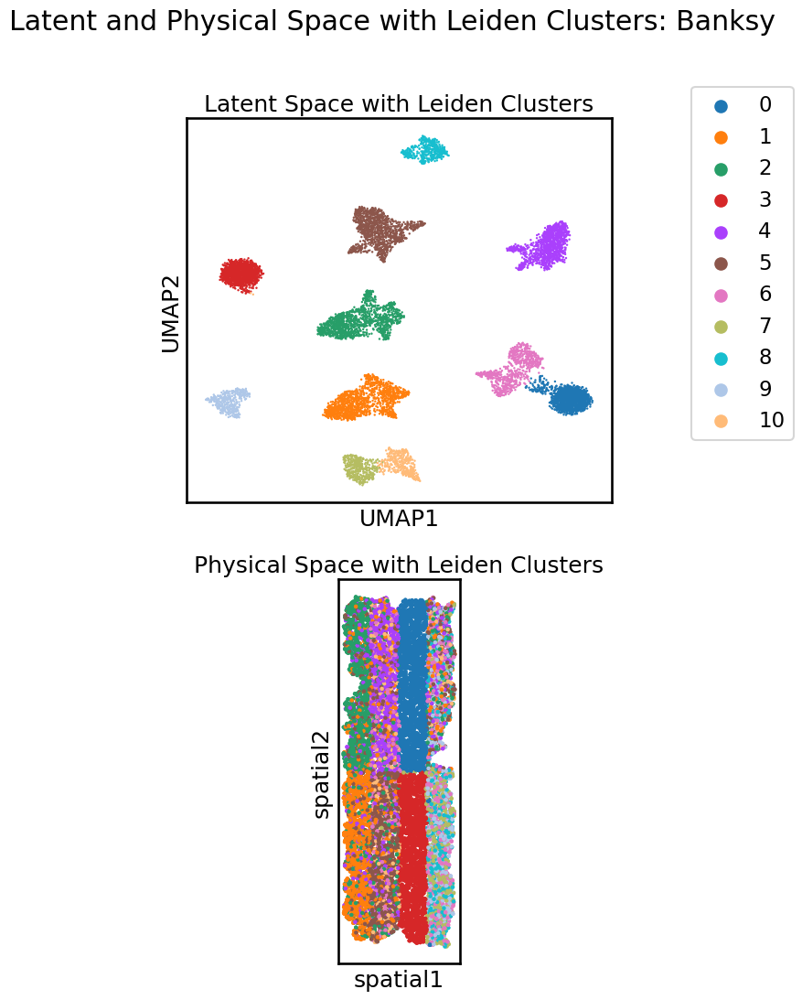


Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.02 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.28 s ----

---- Ran generate_spatial_distance_graph in 0.04 s ----

---- Ran theta_from_spatial_graph in 0.07 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.37 s ----

Runtime Jul-04-2024-10-42

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


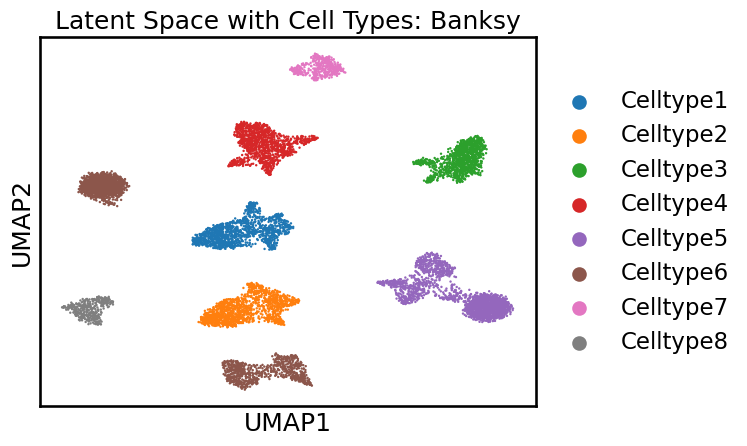

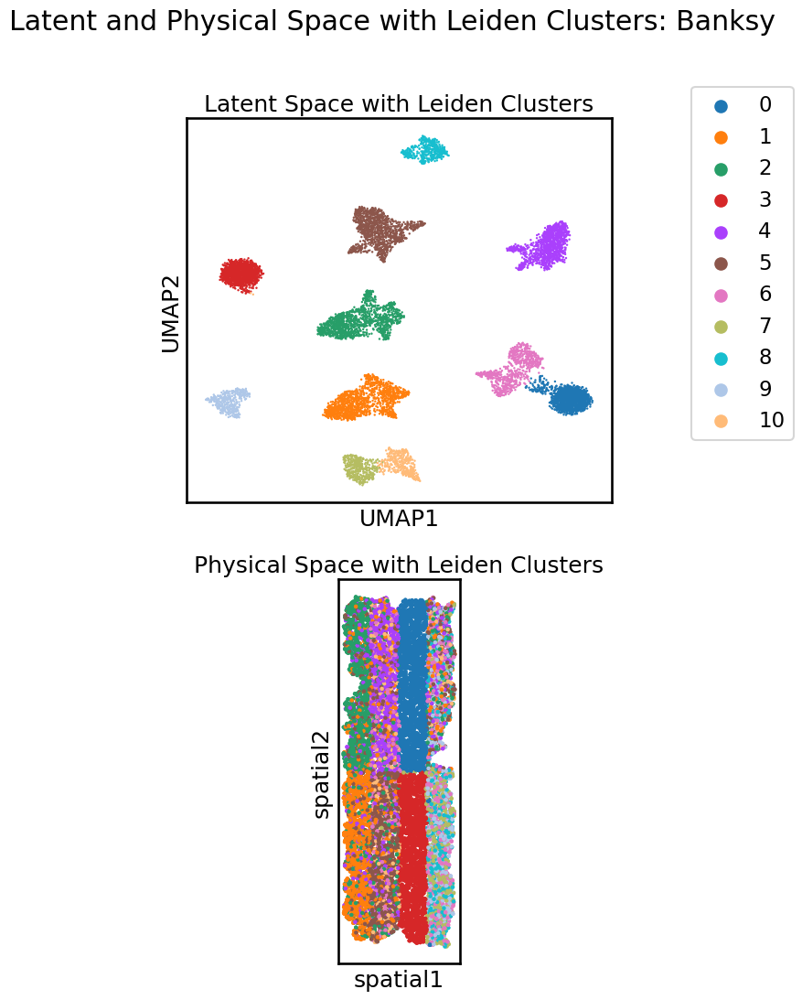


Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.03 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.29 s ----

---- Ran generate_spatial_distance_graph in 0.04 s ----

---- Ran theta_from_spatial_graph in 0.07 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.38 s ----

Runtime Jul-04-2024-10-43

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


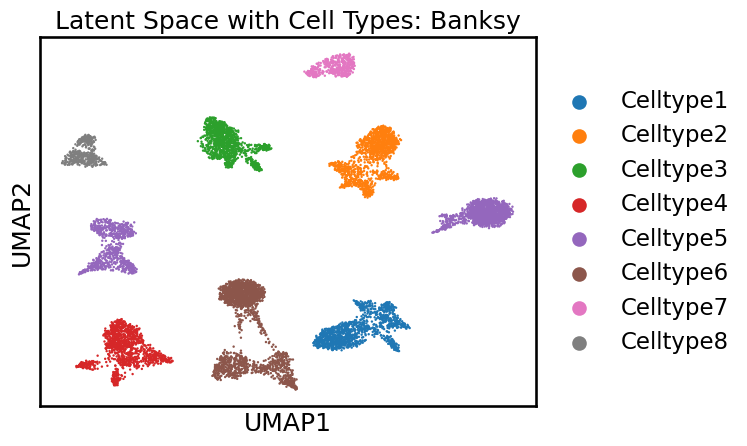

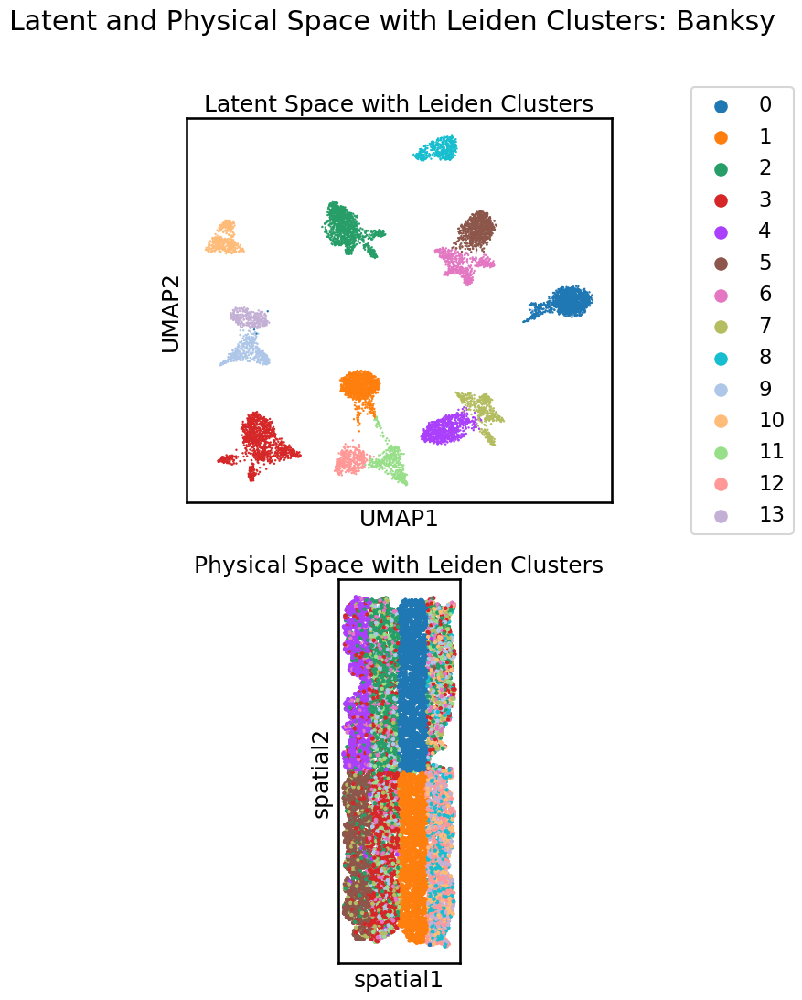


Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.03 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.30 s ----

---- Ran generate_spatial_distance_graph in 0.05 s ----

---- Ran theta_from_spatial_graph in 0.08 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.40 s ----

Runtime Jul-04-2024-10-45

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


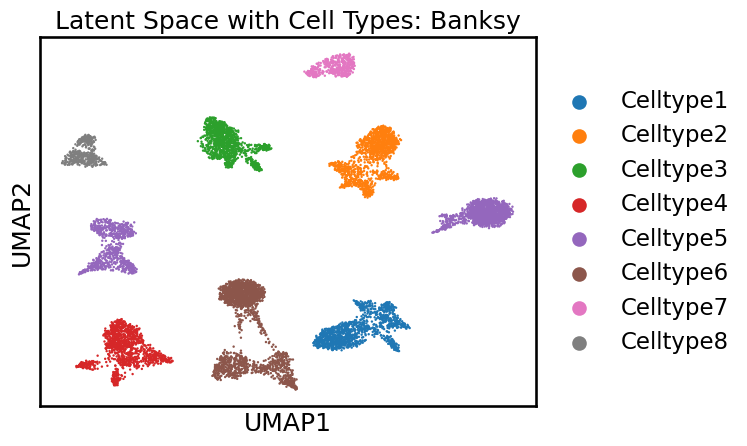

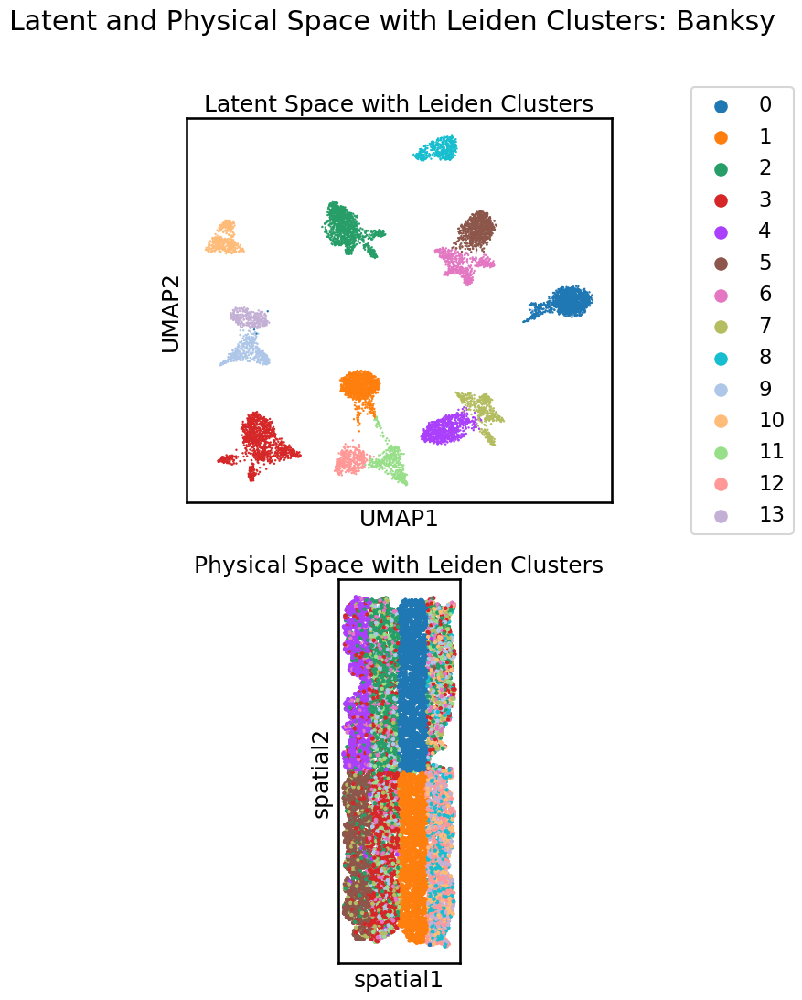


Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.04 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.29 s ----

---- Ran generate_spatial_distance_graph in 0.06 s ----

---- Ran theta_from_spatial_graph in 0.07 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.40 s ----

Runtime Jul-04-2024-10-46

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


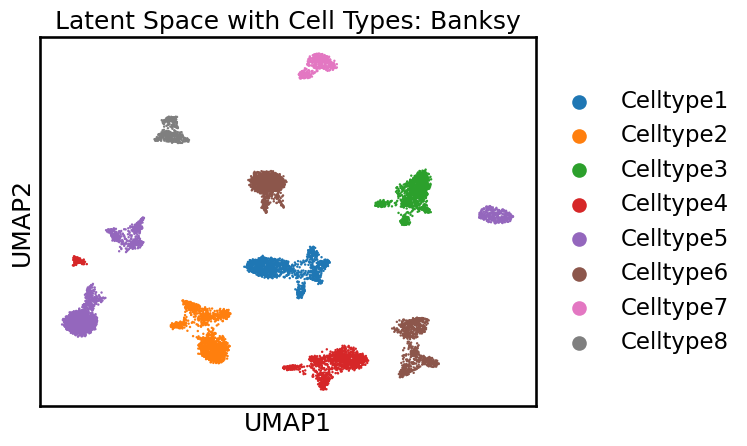

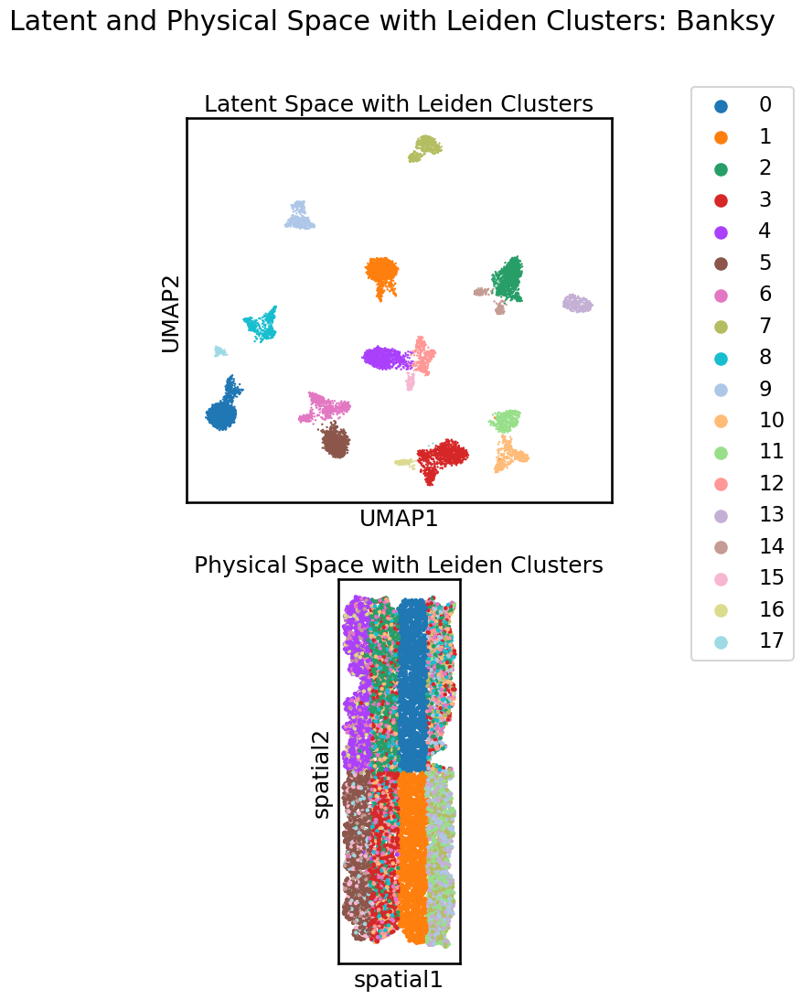


Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----


Median distance to closest cell = 29.075597237845876

---- Ran median_dist_to_nearest_neighbour in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.04 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.31 s ----

---- Ran generate_spatial_distance_graph in 0.06 s ----

---- Ran theta_from_spatial_graph in 0.08 s ----

---- Ran row_normalize in 0.03 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.42 s ----

Runtime Jul-04-2024-10-47

1354 genes to be analysed:
Gene List:
Index(['ENSG00000039068', 'ENSG00000170558', 'ENSG00000062038',
       'ENSG00000179776', 'ENSG00000113361', 'ENSG00000081138',
       'ENSG00000182985', 'ENSG00000162706', 'ENSG00000079385',
       'ENSG00000105388',
       ...
       'ENSG00000137868', 'ENSG00000182220', 'ENSG00000101916',
       'ENSG00000088827', 'ENSG00000117400', 'ENSG00

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


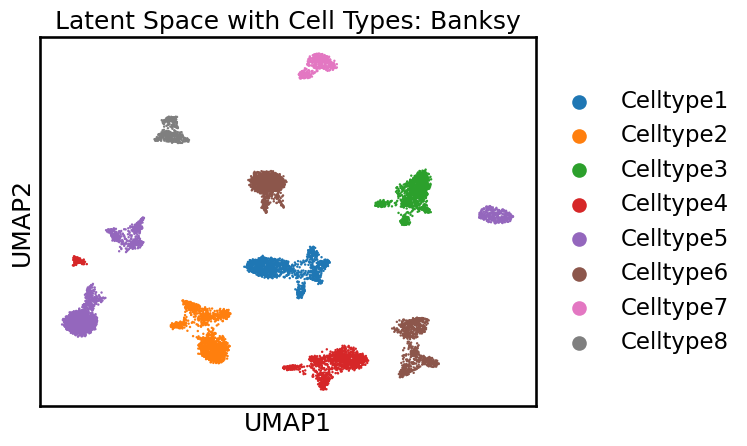

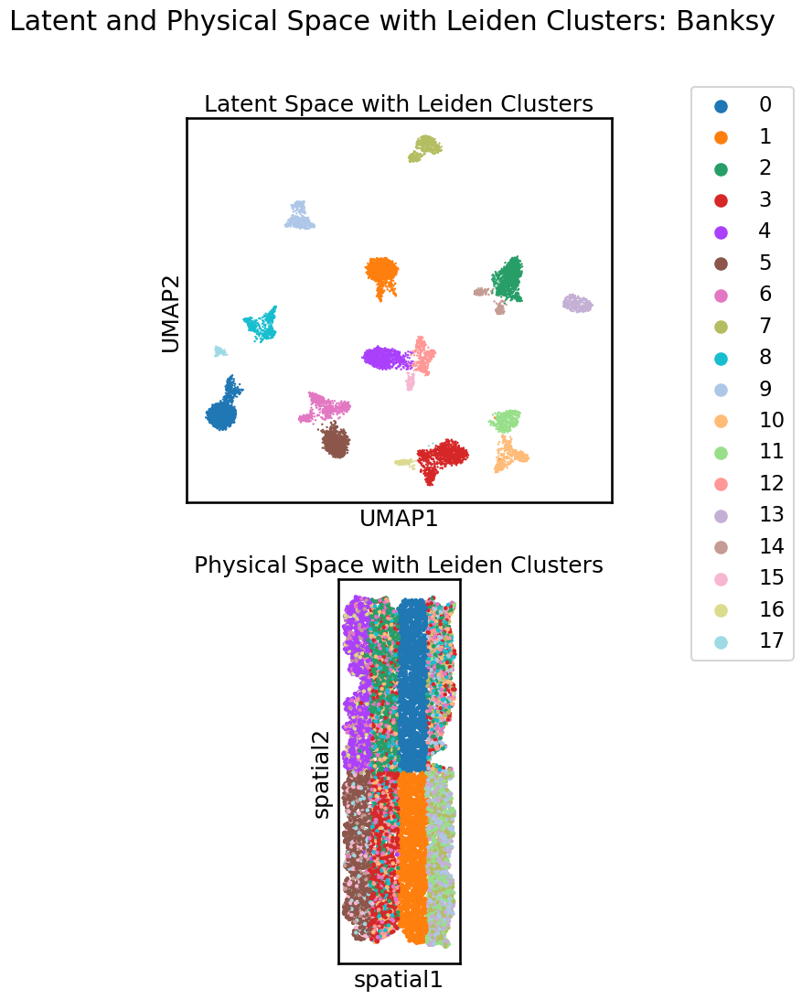

In [54]:
adata = sc.read('../sim_ref_1354fts_10000locs_8r_8c_20p_3fc.h5ad')
x_coordinates = adata.obs['x'].values
y_coordinates = adata.obs['y'].values
# Combine 'x' and 'y' into a single array of shape (n_obs, 2)
spatial_coordinates = np.vstack((x_coordinates, y_coordinates)).T
# Add the spatial coordinates to the obsm attribute
adata.obsm['spatial'] = spatial_coordinates
dataset_name = 'sim_ref_1354fts_10000locs_8r_8c_20p_3fc'
label_cats = ["cell_type"]
cell_type_key =label_cats[0]
raw_y, raw_x , adata = load_data(adata, coord_keys = coord_keys, preprocess = False)
train_banksy(adata,dataset_name, label_cats, cell_type_key)



In [14]:
adata = sc.read('../nanostring_cosmx_human_brain.h5ad')
spatial_coords = adata.obsm['spatial']
# Create DataFrame with x and y columns
spatial_df = pd.DataFrame(spatial_coords, columns=['x', 'y'], index=adata.obs.index)

# Add x and y columns to adata.obs
adata.obs['x'] = spatial_df['x']
adata.obs['y'] = spatial_df['y']



Median distance to closest cell = 11.472335901243756

---- Ran median_dist_to_nearest_neighbour in 0.58 s ----


Median distance to closest cell = 11.472335901243756

---- Ran median_dist_to_nearest_neighbour in 0.57 s ----

---- Ran generate_spatial_distance_graph in 1.25 s ----

---- Ran row_normalize in 0.56 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 5.94 s ----

---- Ran generate_spatial_distance_graph in 1.91 s ----

---- Ran theta_from_spatial_graph in 1.33 s ----

---- Ran row_normalize in 0.53 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 8.26 s ----

Runtime Jul-09-2024-07-03

6078 genes to be analysed:
Gene List:
Index(['A1BG', 'A2M', 'AAAS', 'AAK1', 'AAMP', 'AARS1', 'AASS', 'AATK', 'ABAT',
       'ABCA1',
       ...
       'ZNF804A', 'ZNRF1', 'ZNRF2', 'ZNRF3', 'ZP3', 'ZSWIM6', 'ZWINT',
       'ZYG11B', 'ZYX', 'ZZZ3'],
      dtype='object', length=6078)

Decay Type: scaled_gaussian
Weights Object: {'weights': {0: <188686x188686 sparse matrix of type '<

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/scanpy/plotting/_tools/

/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:946: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


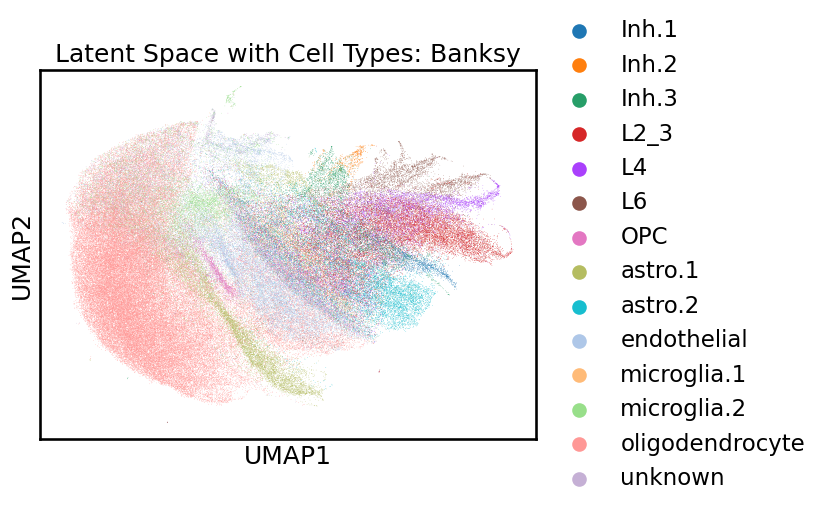

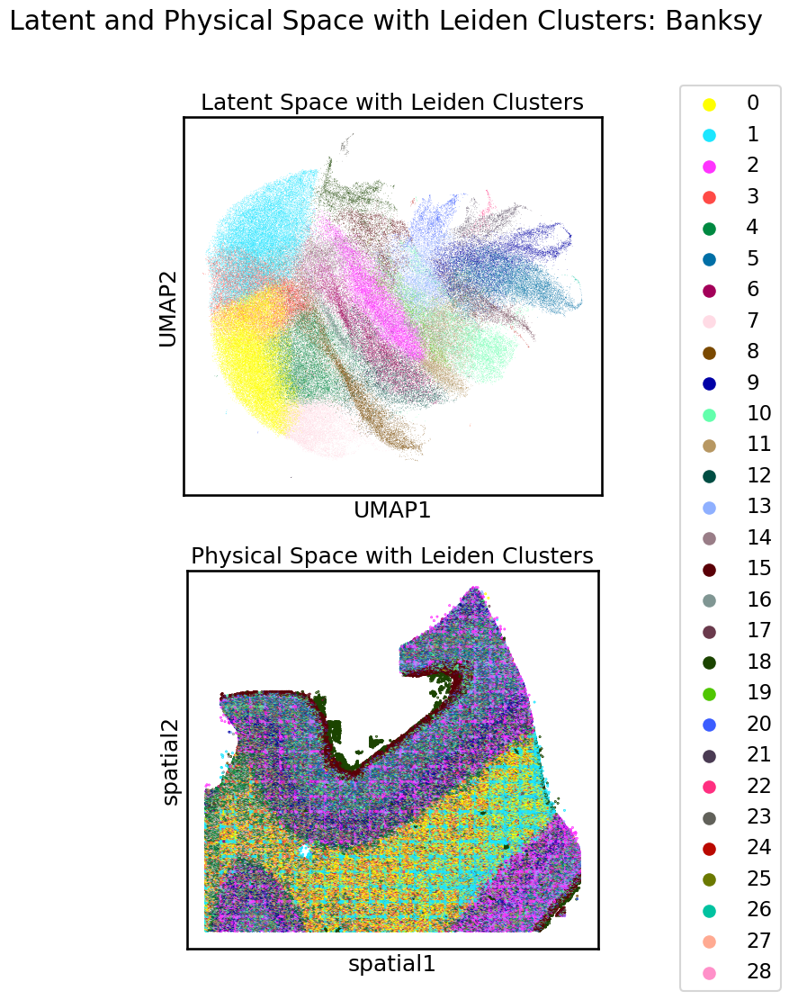

scores------ [{'n_neighbors': 4, 'run_number': 1, 'clf_category': 'cell_type', 'nmi_score': 0.2757828295249074, 'ari_score': 0.49877771122850517}]


/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/nfs/users/nfs_a/ay8/miniconda3/envs/banksy/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stab

In [ ]:
dataset_name = 'nanostring_cosmx_human_brain'
label_cats = ["cell_type", "niche_type"]
cell_type_key =label_cats[0]
raw_y, raw_x , adata = load_data(adata, coord_keys = coord_keys, preprocess = False)
train_banksy(adata,dataset_name, label_cats, cell_type_key)